In [28]:
# Imports & config

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb

sns.set(style="whitegrid")

TARGET_COL = "Churn Flag"

# Paths – adjust if your structure differs
RAW_TRAIN_PATH = "D:/Omar/Side Projects/Recommender System/data/bank_customer_churn_copy.csv"   # original full dataset
NEW_CUSTOMERS_PATH = "D:/Omar/Side Projects/Recommender System/data/new_customer_data.csv"          # your ~15k new records
PROCESSED_DIR = "processed_bank"
MODEL_PATH = "models/xgb_bank_churn.json"


In [29]:
# Load processed training schema & model
# use the processed train parquet from Notebook 1 to know which features the model expects.

# Load processed training data to get feature schema
train_proc = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
feature_cols = [c for c in train_proc.columns if c != TARGET_COL]

print("Processed train shape:", train_proc.shape)
print("Number of feature columns:", len(feature_cols))


# Load trained XGBoost model
model = xgb.XGBClassifier()
model.load_model(MODEL_PATH)
print("Loaded XGBoost model from:", MODEL_PATH)


Processed train shape: (60000, 25)
Number of feature columns: 24
Loaded XGBoost model from: models/xgb_bank_churn.json


In [30]:
# Define columns to drop (same as Notebook 1)

# drop IDs / leakage in exactly the same way

cols_to_drop = [
    "CustomerId",
    "Surname",
    "First Name",
    "Address",
    "Contact Information",
    "Date of Birth",   # raw DOB not used
    "Churn Reason",
    "Churn Date",
]


In [31]:
# Load raw training data for Occupation frequency map

# To frequency-encode Occupation for new customers, we need a reference distribution.
# We’ll compute it from the original training CSV (same dataset you used for Notebook 1)

# Load full original dataset to build Occupation frequency map
df_raw_train = pd.read_csv(RAW_TRAIN_PATH)

# Drop same leakage/ID columns
df_raw_train_model = df_raw_train.drop(columns=cols_to_drop, errors="ignore")

if "Occupation" in df_raw_train_model.columns:
    occupation_freq_map = df_raw_train_model["Occupation"].value_counts()
else:
    occupation_freq_map = None

print("Occupation freq map built with", len(occupation_freq_map) if occupation_freq_map is not None else 0, "entries")


Occupation freq map built with 639 entries


In [32]:
# Define the same feature engineering function as Notebook 1

# This must match the logic we used there (tenure_bucket, high_balance, has_complaints, Occupation_freq).

def add_engineered_features(df_in, train_reference=None, occupation_freq_map=None):
    """
    Add the same engineered features as in Notebook 1:
    - tenure_bucket
    - high_balance (based on training median)
    - has_complaints
    - Occupation_freq (frequency encoding)
    """
    df = df_in.copy()

    # Tenure bucket
    if "Customer Tenure" in df.columns:
        df["tenure_bucket"] = pd.cut(
            df["Customer Tenure"],
            bins=[0, 6, 12, 36, 100],
            labels=["0-6m", "6-12m", "1-3y", "3y+"]
        )

    # High-balance flag (use training median for consistency)
    if "Balance" in df.columns and train_reference is not None and "Balance" in train_reference.columns:
        balance_median = train_reference["Balance"].median()
        df["high_balance"] = (df["Balance"] > balance_median).astype(int)

    # Complaints flag
    if "NumComplaints" in df.columns:
        df["has_complaints"] = (df["NumComplaints"] > 0).astype(int)

    # Occupation frequency encoding (high cardinality → numeric)
    if "Occupation" in df.columns and occupation_freq_map is not None:
        df["Occupation_freq"] = df["Occupation"].map(occupation_freq_map).fillna(0)
        df = df.drop(columns=["Occupation"])

    return df


In [33]:
# Define OHE to match training encoding

# We will one-hot encode only the same low-cardinality categoricals as before 
# and then align to the training feature columns.

def encode_new_data(df_fe, train_feature_cols, desired_cat_cols=None):
    """
    One-hot encode new data using the same categorical columns, then
    align with training feature columns (train_feature_cols).
    """
    if desired_cat_cols is None:
        desired_cat_cols = [
            "Gender",
            "Marital Status",
            "Education Level",
            "Customer Segment",
            "Preferred Communication Channel",
            "tenure_bucket",
        ]

    cat_cols = [c for c in desired_cat_cols if c in df_fe.columns]
    print("One-hot encoding for new data:", cat_cols)

    new_enc = pd.get_dummies(df_fe, columns=cat_cols, drop_first=True)

    # Align with training feature columns (right join: keep only training features)
    train_feature_df = train_proc[train_feature_cols]

    new_enc_aligned, _ = new_enc.align(
        train_feature_df,
        join="right",
        axis=1,
        fill_value=0
    )

    # Assert column order match
    assert list(new_enc_aligned.columns) == list(train_feature_cols)

    return new_enc_aligned



In [34]:
# Load new customers & preprocess

# Load new customers (no churn labels)
new_df_raw = pd.read_csv(NEW_CUSTOMERS_PATH)

print("New customers shape:", new_df_raw.shape)
new_df_raw.head()


New customers shape: (15640, 24)


,CustomerId,Surname,First Name,Date of Birth,Gender,Marital Status,Number of Dependents,Occupation,Income,Education Level,...,Preferred Communication Channel,Credit Score,Credit History Length,Outstanding Loans,Churn Flag,Churn Reason,Churn Date,Balance,NumOfProducts,NumComplaints
0,44443b92-ed64-4f06-ac85-4bf964af7d93,Parker,Nicholas,6/16/1967,Female,Single,0,Recruitment consultant,19067.37,Bachelor's,...,Phone,751,8,35627.19,0,NaN,NaN,192324.39,3,9
1,2e49de39-f94d-4118-aa0e-a43398548414,Barker,Randall,12/29/1993,Female,Divorced,1,"Engineer, control and instrumentation",43382.49,Diploma,...,Email,758,23,23163.67,0,NaN,NaN,65369.02,3,2
2,9ae7a247-c788-446a-b4f0-3262b4359cc7,Huerta,Ryan,2/11/2000,Male,Single,3,Intelligence analyst,99266.78,Bachelor's,...,Email,826,4,6671.15,0,NaN,NaN,245409.33,2,9
3,1d2b578f-2611-46a6-8940-d2656265319a,Acevedo,Whitney,7/19/1983,Female,Married,5,"Designer, ceramics/pottery",19823.61,Bachelor's,...,Email,706,22,21432.59,0,NaN,NaN,173747.24,3,6
4,938e3422-da0d-4ac1-b929-703d6cdeba37,Love,Crystal,8/24/1970,Female,Divorced,4,Public house manager,53061.96,High School,...,Email,743,27,31228.91,0,NaN,NaN,39739.19,5,6


In [35]:
# Drop the same leakage/ID columns:

new_df_model = new_df_raw.drop(columns=cols_to_drop, errors="ignore")
print("Columns in new_df_model:", new_df_model.columns.tolist())


Columns in new_df_model: ['Gender', 'Marital Status', 'Number of Dependents', 'Occupation', 'Income', 'Education Level', 'Customer Tenure', 'Customer Segment', 'Preferred Communication Channel', 'Credit Score', 'Credit History Length', 'Outstanding Loans', 'Churn Flag', 'Balance', 'NumOfProducts', 'NumComplaints']


In [36]:
# Apply feature engineering:

new_df_fe = add_engineered_features(
    new_df_model,
    train_reference=df_raw_train_model,      # for balance median
    occupation_freq_map=occupation_freq_map  # for Occupation_freq
)

new_df_fe.head()


,Gender,Marital Status,Number of Dependents,Income,Education Level,Customer Tenure,Customer Segment,Preferred Communication Channel,Credit Score,Credit History Length,Outstanding Loans,Churn Flag,Balance,NumOfProducts,NumComplaints,tenure_bucket,high_balance,has_complaints,Occupation_freq
0,Female,Single,0,19067.37,Bachelor's,27,Retail,Phone,751,8,35627.19,0,192324.39,3,9,1-3y,1,1,148
1,Female,Divorced,1,43382.49,Diploma,20,Retail,Email,758,23,23163.67,0,65369.02,3,2,1-3y,0,1,165
2,Male,Single,3,99266.78,Bachelor's,17,SME,Email,826,4,6671.15,0,245409.33,2,9,1-3y,1,1,162
3,Female,Married,5,19823.61,Bachelor's,27,Corporate,Email,706,22,21432.59,0,173747.24,3,6,1-3y,1,1,164
4,Female,Divorced,4,53061.96,High School,5,Retail,Email,743,27,31228.91,0,39739.19,5,6,0-6m,0,1,163


In [37]:
# Encode & align features for model input

new_enc = encode_new_data(new_df_fe, train_feature_cols=feature_cols)

print("Encoded new data shape:", new_enc.shape)
print("Any object columns?", new_enc.select_dtypes(include="object").columns.tolist())


One-hot encoding for new data: ['Gender', 'Marital Status', 'Education Level', 'Customer Segment', 'Preferred Communication Channel', 'tenure_bucket']
Encoded new data shape: (15640, 24)
Any object columns? []


In [38]:
# Predict churn probabilities for new customers

churn_scores = model.predict_proba(new_enc)[:, 1]
new_df_fe["churn_score"] = churn_scores

new_df_fe["churn_score"].describe()


count    1.564000e+04
mean     1.401395e-01
std      3.253449e-01
min      4.681350e-08
25%      3.308476e-06
50%      3.194682e-05
75%      1.604750e-03
max      9.999967e-01
Name: churn_score, dtype: float64

In [39]:
# CLV and expected lost value

# Use the same CLV formula as in Notebook 2

new_df_fe["clv_est"] = (
    new_df_fe.get("Balance", 0)
    + 0.5 * new_df_fe.get("Outstanding Loans", 0)
    + 200 * new_df_fe.get("NumOfProducts", 0)
)

new_df_fe["expected_lost_value"] = new_df_fe["churn_score"] * new_df_fe["clv_est"]

new_df_fe[["churn_score", "clv_est", "expected_lost_value"]].describe()


,churn_score,clv_est,expected_lost_value
count,1.564000e+04,15640.000000,15640.000000
mean,1.401395e-01,137526.845049,6097.201784
std,3.253449e-01,72670.303198,15937.934154
min,4.681350e-08,1654.160000,0.004193
25%,3.308476e-06,74841.483750,0.514689
50%,3.194682e-05,137457.487500,4.856131
75%,1.604750e-03,200585.902500,157.859897
max,9.999967e-01,274632.155000,117245.544860


In [40]:
# Segmentation (same logic as Notebook 2)

def assign_segment(row, balance_median=None):
    if balance_median is None and "Balance" in new_df_fe.columns:
        balance_median = new_df_fe["Balance"].median()
    balance = row.get("Balance", 0)
    products = row.get("NumOfProducts", 0)
    complaints = row.get("NumOfComplaints", 0)
    tenure = row.get("Customer Tenure", 0)

    if balance > balance_median and products >= 3:
        return "affluent_multi_product"
    if complaints > 0:
        return "high_complaint_risk"
    if tenure < 6:
        return "new_customer"
    if products == 1:
        return "single_product_low_engagement"
    return "mass_market"

balance_median_new = new_df_fe["Balance"].median() if "Balance" in new_df_fe.columns else None
new_df_fe["segment"] = new_df_fe.apply(assign_segment, axis=1, balance_median=balance_median_new)

new_df_fe["segment"].value_counts(normalize=True)


segment
mass_market                      0.419821
affluent_multi_product           0.295205
single_product_low_engagement    0.167327
new_customer                     0.117647
Name: proportion, dtype: float64

In [41]:
# Retention recommendation rules

# Use same rule set as Notebook 2: target top 20% by churn_score

cutoff = new_df_fe["churn_score"].quantile(0.8)
cutoff


0.019515427947044417

In [42]:
def recommend_action(row, cutoff=cutoff):
    if row["churn_score"] < cutoff:
        return "no_action"

    seg = row["segment"]

    if seg == "affluent_multi_product":
        return "personal_banker_outreach_rate_offer"
    if seg == "high_complaint_risk":
        return "service_recovery_and_fee_refund"
    if seg == "new_customer":
        return "onboarding_support_and_welcome_offer"
    if seg == "single_product_low_engagement":
        return "cross_sell_bundle_offer"
    return "general_retention_email"

new_df_fe["recommended_action"] = new_df_fe.apply(recommend_action, axis=1)
new_df_fe["recommended_action"].value_counts()


recommended_action
no_action                               12512
general_retention_email                  1829
cross_sell_bundle_offer                   765
onboarding_support_and_welcome_offer      534
Name: count, dtype: int64

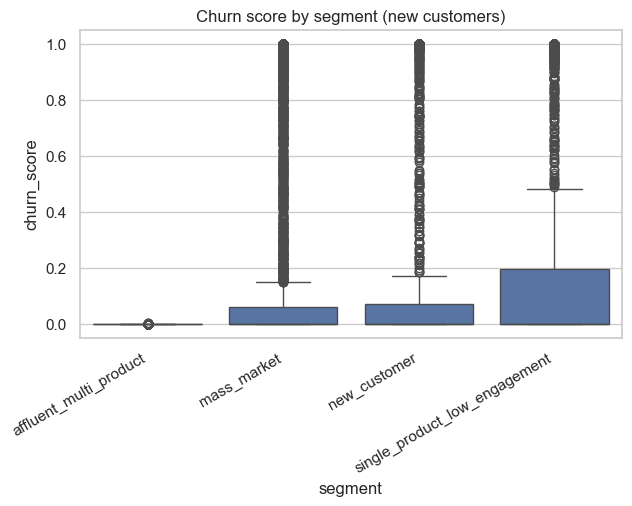

In [43]:
# Sanity plots

plt.figure(figsize=(7,4))
sns.boxplot(data=new_df_fe, x="segment", y="churn_score")
plt.xticks(rotation=30, ha="right")
plt.title("Churn score by segment (new customers)")
plt.show()


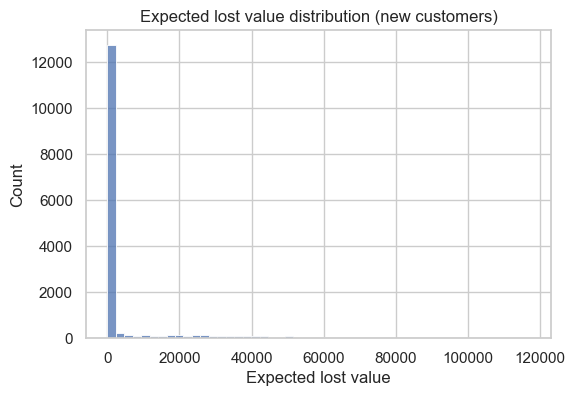

In [44]:
plt.figure(figsize=(6,4))
sns.histplot(new_df_fe["expected_lost_value"], bins=50)
plt.title("Expected lost value distribution (new customers)")
plt.xlabel("Expected lost value")
plt.ylabel("Count")
plt.show()

In [45]:
# Build final export table

os.makedirs("outputs_bank", exist_ok=True)

# Try to keep an ID column from the original raw new_df_raw (e.g. CustomerId)
id_candidates = [c for c in new_df_raw.columns if "id" in c.lower() or "customer" in c.lower()]
id_cols = id_candidates  # usually ["CustomerId"]

base_cols = [
    "churn_score",
    "clv_est",
    "expected_lost_value",
    "segment",
    "recommended_action",
]

extra_cols = [c for c in ["Balance", "NumOfProducts", "Customer Tenure", "NumOfComplaints"] if c in new_df_fe.columns]

export_cols = id_cols + base_cols + extra_cols
export_cols = list(dict.fromkeys(export_cols))  # remove duplicates but keep order

df_export = pd.concat(
    [new_df_raw[id_cols].reset_index(drop=True),  # raw ID columns
     new_df_fe[base_cols + extra_cols].reset_index(drop=True)],
    axis=1
)

df_export.head()


,CustomerId,Customer Tenure,Customer Segment,churn_score,clv_est,expected_lost_value,segment,recommended_action,Balance,NumOfProducts,Customer Tenure
0,44443b92-ed64-4f06-ac85-4bf964af7d93,27,Retail,1.442095e-05,210737.985,3.039041,affluent_multi_product,no_action,192324.39,3,27
1,2e49de39-f94d-4118-aa0e-a43398548414,20,Retail,6.861204e-07,77550.855,0.053209,mass_market,no_action,65369.02,3,20
2,9ae7a247-c788-446a-b4f0-3262b4359cc7,17,SME,1.241112e-05,249144.905,3.092167,mass_market,no_action,245409.33,2,17
3,1d2b578f-2611-46a6-8940-d2656265319a,27,Corporate,6.138564e-06,185063.535,1.136024,affluent_multi_product,no_action,173747.24,3,27
4,938e3422-da0d-4ac1-b929-703d6cdeba37,5,Retail,1.924397e-05,56353.645,1.084468,new_customer,no_action,39739.19,5,5


In [46]:
# Save CSV with new customers scores + actions

output_path = "outputs_bank/new_customers_churn_predictions.csv"
df_export.to_csv(output_path, index=False)
print("Saved new customer predictions to:", output_path)


Saved new customer predictions to: outputs_bank/new_customers_churn_predictions.csv


Extra summary stats for Notebook 3

In [47]:
# Cell A – How many customers we recommend contacting?

total_customers = len(df_export)
to_contact = (df_export["recommended_action"] != "no_action").sum()
contact_rate = to_contact / total_customers

print(f"Total new customers: {total_customers}")
print(f"Customers flagged for outreach: {to_contact} ({contact_rate:.1%})")


Total new customers: 15640
Customers flagged for outreach: 3128 (20.0%)


In [48]:
# Cell B – What share of expected lost value do those customers represent?

total_elv = df_export["expected_lost_value"].sum()
elv_targeted = df_export.loc[df_export["recommended_action"] != "no_action", "expected_lost_value"].sum()

coverage = elv_targeted / total_elv if total_elv > 0 else np.nan

print(f"Total expected lost value (all new customers): {total_elv:,.2f}")
print(f"Expected lost value within targeted group:     {elv_targeted:,.2f}")
print(f"Share of expected loss covered by actions:     {coverage:.1%}")

Total expected lost value (all new customers): 95,360,235.90
Expected lost value within targeted group:     94,817,323.35
Share of expected loss covered by actions:     99.4%


In [49]:
# Cell C – Breakdown of actions by segment

action_segment_pivot = (
    df_export
    .groupby(["segment", "recommended_action"])
    .size()
    .reset_index(name="count")
)

action_segment_pivot

,segment,recommended_action,count
0,affluent_multi_product,no_action,4617
1,mass_market,general_retention_email,1829
2,mass_market,no_action,4737
3,new_customer,no_action,1306
4,new_customer,onboarding_support_and_welcome_offer,534
5,single_product_low_engagement,cross_sell_bundle_offer,765
6,single_product_low_engagement,no_action,1852


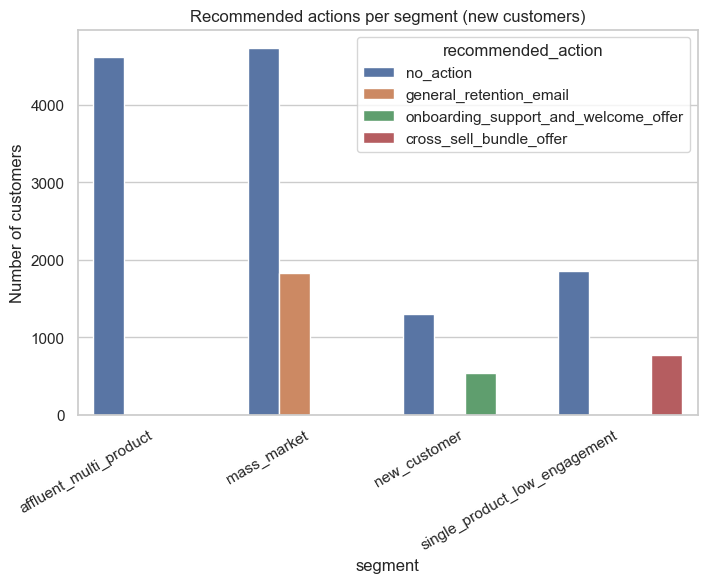

In [50]:
plt.figure(figsize=(8,5))
pivot_plot = (
    df_export
    .groupby(["segment", "recommended_action"])
    .size()
    .reset_index(name="count")
)

sns.barplot(
    data=pivot_plot,
    x="segment",
    y="count",
    hue="recommended_action"
)
plt.xticks(rotation=30, ha="right")
plt.title("Recommended actions per segment (new customers)")
plt.ylabel("Number of customers")
plt.show()
